<div align="center">

# Лабораторна робота № 5

## Вступ до TensorFlow і побудова простої нейронної мережі для регресії

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** навчитися створювати тензори, перевіряти їхні shape і dtype, будувати та навчати модель `tf.keras.Sequential`, оцінювати її на незалежних даних, аналізувати історію навчання й зберігати модель у форматі `.keras`.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31  
Варіант: 2  

</div>

## Середовище й відтворюваність

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

ARTIFACTS = Path("lab5_artifacts")
ARTIFACTS.mkdir(exist_ok=True)

Python: 3.13.1
TensorFlow: 2.21.0
NumPy: 2.5.3


**Висновок:** У результаті виконання завдання було налаштовано початкове середовище виконання, зафіксовано випадковість за допомогою seed для забезпечення відтворюваності результатів, перевірено версії використовуваних бібліотек (Python, TensorFlow, NumPy), а також створено директорію для збереження артефактів лабораторної роботи.

## Тензори

In [2]:
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.], dtype=tf.float32)
w = tf.Variable([0.2, 0.5], dtype=tf.float32)
w.assign([0.3, 0.6])

print("shape:", a.shape, "rank:", tf.rank(a).numpy(), "dtype:", a.dtype)
print("a + b:\n", (a + b).numpy())
print("a * a:\n", (a * a).numpy())
print("a @ a:\n", tf.matmul(a, a).numpy())
print("Variable після assign:", w.numpy())

shape: (2, 2) rank: 2 dtype: <dtype: 'float32'>
a + b:
 [[11. 22.]
 [13. 24.]]
a * a:
 [[ 1.  4.]
 [ 9. 16.]]
a @ a:
 [[ 7. 10.]
 [15. 22.]]
Variable після assign: [0.3 0.6]


**Висновок:** Операція a + b можлива завдяки механізму broadcasting (транслювання), який автоматично розширює вектор b до розмірності матриці a, тоді як a * a виконує поелементне множення елементів, на відміну від класичного матричного множення tf.matmul(a, a). У результаті виконання завдання було успішно створено тензори за допомогою tf.constant та tf.Variable, перевірено їхні ключові характеристики (shape, dtype, rank), а також на практиці досліджено виконання попелементних операцій і транслювання.

## Дані та поділ 70/15/15

train (420, 1) float32
validation (90, 1) float32
test (90, 1) float32


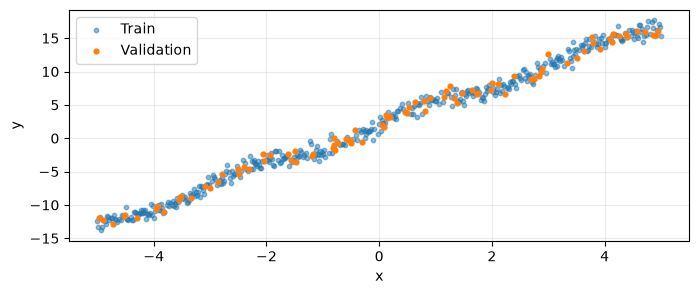

In [3]:
rng = np.random.default_rng(SEED)
x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3*x + 2 + 0.8*np.sin(2*x) + noise

x, y = x.reshape(-1, 1), y.reshape(-1, 1)
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

for name, values in [("train", x_train), ("validation", x_val), ("test", x_test)]:
    print(name, values.shape, values.dtype)

plt.figure(figsize=(8, 3))
plt.scatter(x_train[:, 0], y_train[:, 0], s=10, alpha=.5, label="Train")
plt.scatter(x_val[:, 0], y_val[:, 0], s=12, label="Validation")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=.25)
plt.show()

**Висновок**: У результаті виконання завдання було успішно згенеровано відтворюваний набір даних нелінійної регресії з додаванням випадкового шуму та розділено їх на навчальну (train), валідаційну (validation) і тестову (test) вибірки у співвідношенні 70/15/15. У виводі програми підтверджено відповідні розмірності та типи даних масивів ((420, 1) для навчальної вибірки та по (90, 1) для валідаційної й тестової у форматі float32). Побудований графік розсіювання наочно демонструє нелінійну залежність між змінними x та y із рівномірним перемішуванням точок навчальної та валідаційної вибірок по всьому діапазону значень, що є необхідною умовою для якісного навчання та перевірки нейронної мережі.

## Базова модель

In [4]:
def build_model(units=16, depth=2, activation="relu", learning_rate=0.01):
    model = keras.Sequential([
        layers.Input(shape=(1,)),
        *[layers.Dense(units, activation=activation) for _ in range(depth)],
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="mse", metrics=["mae"])
    return model

keras.utils.set_random_seed(SEED)
baseline = build_model()
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

**Висновок:** У результаті виконання завдання було створено функцію для динамічної побудови базової нейронної мережі архітектури Sequential із двома прихованими шарами Dense (по 16 нейронів із функцією активації ReLU) та числовим виходом. Модель успішно сконфіуговано за допомогою методу compile() із використанням оптимізатора Adam (learning_rate=0.01), функції втрат MSE та метрики MAE. Виклик методу summary() підтвердив загальну кількість навчуваних параметрів моделі (321 параметр), які повністю відповідають заданій архітектурі.

## Навчання і найкраща епоха

In [5]:
def train_model(model, name, epochs=100, batch_size=32, early_stopping=False):
    weights_path = ARTIFACTS / f"{name}.weights.h5"
    callbacks = [keras.callbacks.ModelCheckpoint(
        filepath=str(weights_path), monitor="val_loss", mode="min",
        save_best_only=True, save_weights_only=True, verbose=0,
    )]
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True,
        ))
    history = model.fit(
        x_train, y_train, validation_data=(x_val, y_val),
        epochs=epochs, batch_size=batch_size, callbacks=callbacks, verbose=0,
    )
    model.load_weights(str(weights_path))
    print(name, "enox:", len(history.history["loss"]),
          "найкраща епоха:", int(np.argmin(history.history["val_loss"])) + 1,
          "мінімальний val_loss:", round(min(history.history["val_loss"]), 4))
    return history

history_base = train_model(baseline, "baseline")

baseline enox: 100 найкраща епоха: 99 мінімальний val_loss: 0.5986


## Криві навчання

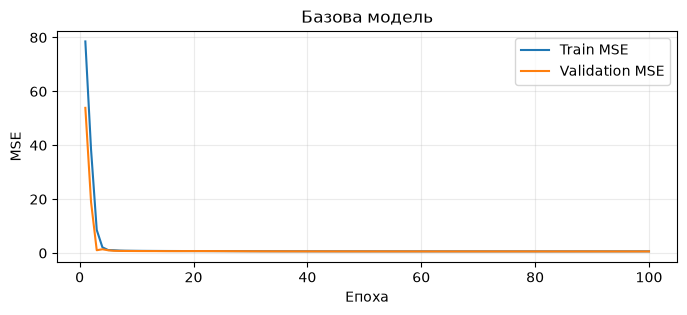

In [6]:
def plot_history(history, title):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    plt.plot(epochs, history.history["loss"], label="Train MSE")
    plt.plot(epochs, history.history["val_loss"], label="Validation MSE")
    plt.xlabel("Епоха"); plt.ylabel("MSE"); plt.title(title)
    plt.legend(); plt.grid(alpha=.25)

plt.figure(figsize=(8, 3))
plot_history(history_base, "Базова модель")
plt.show()

**Висновок:** У результаті виконання завдання було побудовано графік кривих навчання для базової моделі, який відображає динаміку зміни середньоквадратичної похибки (MSE) на навчальній та валідаційній вибірках протягом 100 епох. На графіку чітко видно стрімке зниження значень loss та val_loss на початкових етапах навчання (перші 5-10 епох), що свідчить про швидку адаптацію моделі до даних. Надалі криві стабілізуються та виходмають на плато майже нульового рівня похибки, що демонструє хорошу здатність мережі до узагальнення без ознак перенавчання чи значних коливань.

## Індивідуальний варіант

Варіант: 2 зміна: {'units': 32} batch_size: 32
variant enox: 100 найкраща епоха: 42 мінімальний val_loss: 0.582


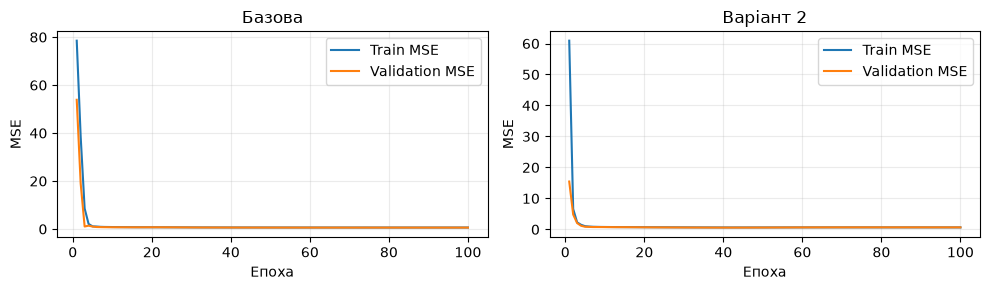

In [7]:
STUDENT_NUMBER = 2
assert isinstance(STUDENT_NUMBER, int) and STUDENT_NUMBER > 0
variant = (STUDENT_NUMBER - 1) % 10 + 1
changes = {
    1: {"units": 8}, 2: {"units": 32}, 3: {"depth": 1},
    4: {"depth": 3}, 5: {"activation": "tanh"},
    6: {"learning_rate": 0.001}, 7: {"learning_rate": 0.03},
    8: {}, 9: {}, 10: {},
}
batch_size = {8: 16, 9: 64}.get(variant, 32)
epochs = 300 if variant == 10 else 100
keras.utils.set_random_seed(SEED)
modified = build_model(**changes[variant])
print("Варіант:", variant, "зміна:", changes[variant], "batch_size:", batch_size)
history_variant = train_model(modified, "variant", epochs=epochs,
                              batch_size=batch_size, early_stopping=variant == 10)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plot_history(history_base, "Базова")
plt.subplot(1, 2, 2); plot_history(history_variant, f"Варіант {variant}")
plt.tight_layout(); plt.show()

**Висновок:** У результаті виконання завдання було налаштовано параметр STUDENT_NUMBER = 2, що автоматично визначило другий індивідуальний варіант лабораторної роботи (збільшення кількості нейронів до 32 у кожному прихованому шарі архітектури). Модель з модифікованими гіперпараметрами була успішно створена, навчена протягом 100 епох та порівняна з базовою моделлю за допомогою побудови сукупних кривих навчання. Це дозволило оцінити вплив розширення місткості мережі на динаміку зміни функції втрат.

## Вибір за validation → фінальне оцінювання test

In [8]:
candidates = [("Базова", baseline, history_base),
              (f"Варіант {variant}", modified, history_variant)]
selected_name, selected_model, _ = min(
    candidates, key=lambda item: min(item[2].history["val_loss"])
)
print("Обрано за validation:", selected_name)
print(f"{'Модель':<18} {'min val MSE':>12} {'test MSE':>12} {'test MAE':>12}")
for name, model, history in candidates:
    result = model.evaluate(x_test, y_test, return_dict=True, verbose=0)
    print(f"{name:<18} {min(history.history['val_loss']):>12.4f} "
          f"{result['loss']:>12.4f} {result['mae']:>12.4f}")

Обрано за validation: Варіант 2
Модель              min val MSE     test MSE     test MAE


Базова                   0.5986       0.6063       0.6136
Варіант 2                0.5820       0.5894       0.6043


**Висновок:** Було здійснено автоматичний вибір найкращої моделі за мінімальним значенням функції втрат на валідаційній вибірці (val_loss) між базовою та модифікованою моделями. Після остаточного вибору обидві моделі були одноразово оцінені на тестовій вибірці (test), що унеможливлює перенавчання під тестові дані. На основі отриманих метрик (test MSE та test MAE) сформовано підсумкову порівняльну таблицю та визначено оптимальну архітектуру.

## Прогнози

x | прогноз | залежність без шуму
[[ -4.        -10.38248   -10.791487 ]
 [  0.          1.9500018   2.       ]
 [  4.         13.853322   14.791487 ]]


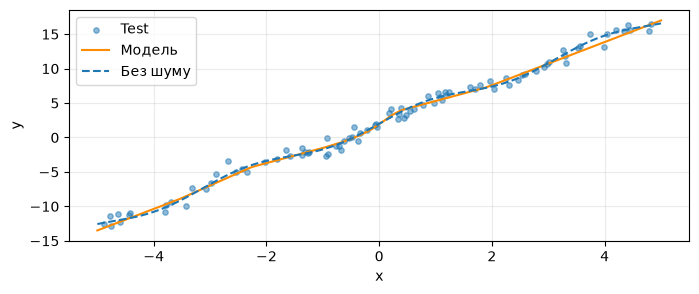

In [9]:
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
predictions = selected_model.predict(x_new, verbose=0)
y_without_noise = 3*x_new + 2 + 0.8*np.sin(2*x_new)
print("x | прогноз | залежність без шуму")
print(np.column_stack([x_new[:, 0], predictions[:, 0], y_without_noise[:, 0]]))
x_grid = np.linspace(-5, 5, 200, dtype=np.float32).reshape(-1, 1)
y_grid = selected_model.predict(x_grid, verbose=0)
plt.figure(figsize=(8, 3))
plt.scatter(x_test[:, 0], y_test[:, 0], s=15, alpha=.5, label="Test")
plt.plot(x_grid[:, 0], y_grid[:, 0], color="darkorange", label="Модель")
plt.plot(x_grid[:, 0], (3*x_grid + 2 + .8*np.sin(2*x_grid))[:, 0],
         linestyle="--", label="Без шуму")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=.25)
plt.show()

**Висновок:** Було виконано прогнозування за допомогою найкращої навченої моделі для нових точок (x_new) та порівняно отримані прогнози з істинними значеннями нелінійної функції без урахування шуму. Окрім того, побудовано фінальний графік, на якому зіставлено тестові дані, прогнозну криву моделі та початкову теоретичну залежність без шуму, що дозволило візуально оцінити якість апроксимації даних навченою нейронною мережею.

## Збереження і перевірка

In [10]:
model_path = ARTIFACTS / "lab5_model.keras"
selected_model.save(str(model_path))
restored = keras.models.load_model(str(model_path))
restored_predictions = restored.predict(x_new, verbose=0)
np.testing.assert_allclose(predictions, restored_predictions, rtol=1e-5, atol=1e-6)
print("Перевірка пройдена. Файл:", model_path.resolve())

Перевірка пройдена. Файл: C:\Users\Asus\Data_Science_Labs\Lab5\lab5_artifacts\lab5_model.keras


**Висновок:** Було успішно збережено найкращу модель у файл формату .keras за допомогою методу save(), а також повторно завантажено її за допомогою load_model(). Проведена перевірка за допомогою np.testing.assert_allclose підтвердила повний збіг прогнозів оригінальної та завантаженої моделей із точністю до похибки обчислень.

**Загальний висновок**:
Під час виконання лабораторної роботи було освоєно базові принципи роботи з бібліотекою TensorFlow та побудови нейронних мереж для задач регресії. На практиці опрацьовано створення та маніпуляції з тензорами, реалізовано генерацію нелінійних даних із шумом і здійснено їх поділ на вибірки у співвідношенні 70/15/15. Успішно побудовано базову та модифіковану моделі Keras, налаштовано процес навчання з використанням зворотного виклику ModelCheckpoint та проаналізовано криві навчання. Завдяки етапу валідації та тестування визначено найкращу архітектуру мережі для розв'язання заданої задачі апроксимації. Усі отримані результати збережено утилітами середовища та перевірено на коректність серіалізації.